# The full pipeline, end to end

This notebook runs the whole workflow, one stage at a time, and shows at each stage how
to swap one component for another. It needs only this package (numpy, scipy,
matplotlib) and takes under a minute.

| stage | what it does | file | swap it by changing |
|---|---|---|---|
| 1 path generation | family + explicit parameters → commanded path | `scanpath/paths.py` | the family name or a parameter |
| 2 instrument model | **case A** path → path, or **case B** image → image | `scanpath/instruments.py` | the model name; the pipeline picks the route |
| 3 evaluation | named quality / distortion metrics | `scanpath/metrics.py` | the metric name |
| 4 exploration and optimisation | grid, random, pattern, DE or GP-based search | `scanpath/optimisation.py` | `sp.SEARCHES[name]`, same arguments |

The objects passed between stages are always the same: a `Budget` and parameters go in,
a commanded `Trajectory` comes out of stage 1, stage 2 returns a realized `Trajectory`
(case A) or an image (case B), stage 3 returns a dictionary of scores, and stage 4 returns
every point it tried plus the best one. Because of that, any path works with any
instrument model, any metric and either optimiser.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))        # scanpath_core (run from notebooks/)
sys.dont_write_bytecode = True
import scanpath as sp

BLUE, ORANGE, AQUA, VIOLET, INK2, GRID, SURFACE = ("#2a78d6", "#eb6834", "#1baf7a",
                                                  "#6250d6", "#52514e", "#e4e3df", "#fcfcfb")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
    "figure.dpi": 110,
})

def tidy(params):
    return {k: round(v, 3) if isinstance(v, float) else v for k, v in params.items()}

def show_image(ax, image, title, budget):
    ax.imshow(image, extent=[-budget.fov_nm / 2, budget.fov_nm / 2] * 2, origin="lower", cmap="gray")
    ax.set_title(title, fontsize=9.5); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

## 0. One place for every choice

Everything below reads from this cell. Change a line here and rerun the notebook to swap
a component; nothing else needs editing.

In [2]:
BUDGET = sp.Budget(fov_nm=100, duration_s=1.0, rate_hz=20_000)   # same for every path
SAMPLE = sp.Sample.synthetic(BUDGET.fov_nm, seed=0)               # ideal image (70 particles)

PATH = ("raster", {"lines": 48, "flyback": 0.1})                  # stage 1
INSTRUMENT = ("lowpass", {"bandwidth_hz": 1500})                  # stage 2, case A ...
IMAGE_MODEL = ("drift_warp", {"vx_nm_s": 5.0, "vy_nm_s": 2.0})    # stage 2, case B
SCORE = "image_nrmse"                                             # stage 3, the one to optimise
SPACE = {"lines": (16, 128, "int"), "flyback": (0.05, 0.8)}       # stage 4, what to explore

print(f"budget: {BUDGET.fov_nm:.0f} nm field, {BUDGET.duration_s:.0f} s, {BUDGET.n:,} samples")

budget: 100 nm field, 1 s, 20,000 samples


## 1. Path generation, with explicit parameters

A path family is a function of time with named parameters, and every parameter has a
default you can read back with `sp.parameters(name)`. Families marked with a **knob**
have one density parameter (lines, turns, spokes…) that `Budget(length_um=…)` can tune
so that every family travels the same distance.

Three kinds of family live in `paths.py`. *Driven curves* (raster, spiral, Lissajous,
closed loops, rose) are written directly as functions of time, so each keeps its natural
motion; a Lissajous stays sinusoidal. *Shapes* (serpentine, radial, Hilbert, hybrid,
strokes) are drawn as a polyline and walked at constant speed. *Dwell paths* (sparse,
pulse lattice) park at sites; the pulse lattice measures only while parked.

In [3]:
print(f"{'family':12s} {'knob':12s} parameters (defaults)")
for name, fn in sp.PATHS.items():
    print(f"{name:12s} {str(fn.knob or '-'):12s} {sp.parameters(name)}")

family       knob         parameters (defaults)
raster       lines        {'lines': 48, 'flyback': 0.1}
spiral       turns        {'turns': 58, 'radius': 1.0}
lissajous    -            {'nx': 30, 'ny': 31, 'phase_deg': 30.0}
closed_loops loops        {'loops': 6, 'radius': 1.0, 'axis_ratio': 1.0, 'angle_deg': 0.0}
rose         cycles       {'order': 3, 'cycles': 3, 'radius': 1.0, 'angle_deg': 0.0}
strokes      strokes      {'strokes': 8, 'radius': 1.0, 'angle_deg': 0.0}
serpentine   lines        {'lines': 62, 'angle_deg': 0.0}
radial       spokes       {'spokes': 64, 'radius': 1.0, 'angle_deg': 0.0}
hybrid       fine_lines   {'fine_lines': 74, 'roi_frac': 0.4, 'coarse_lines': 32}
hilbert      -            {'order': 6}
sparse       -            {'n_points': 64, 'dwell_fraction': 0.875, 'seed': 0}
pulse_lattice -            {'rows': 6, 'columns': 6, 'dwell_fraction': 0.6, 'radius': 1.0}
grid_spiral  pixels       {'pixels': 64, 'direction': 'in'}
n_sequential pixels       {'pixels': 64, '

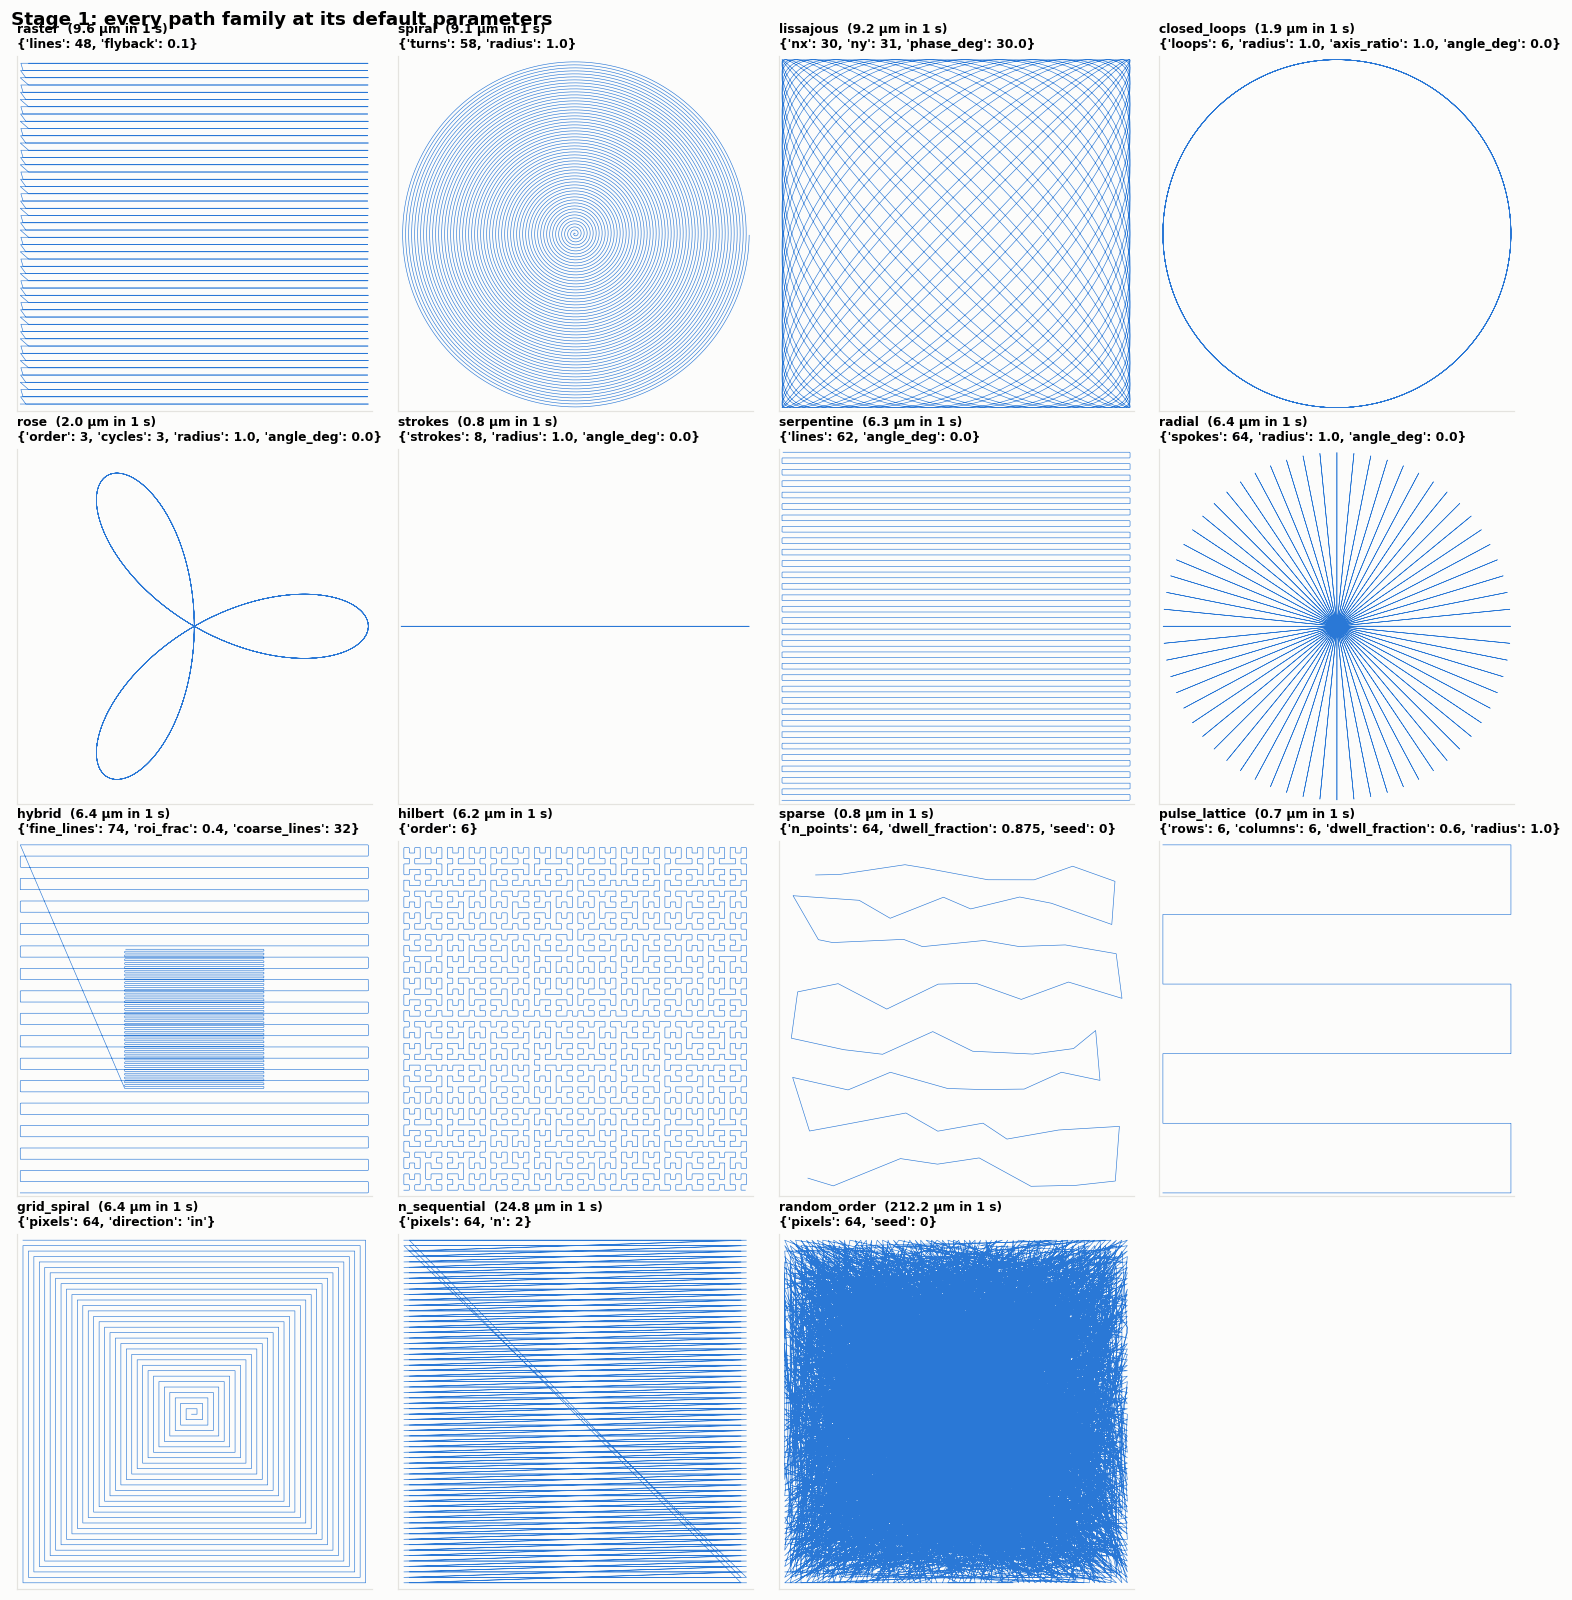

In [4]:
names = list(sp.PATHS)
rows = -(-len(names) // 4)
fig, axes = plt.subplots(rows, 4, figsize=(14, 3.7 * rows))
for ax in axes.flat[len(names):]:
    ax.set_visible(False)
for ax, name in zip(axes.flat, names):
    path = sp.make_path(name, BUDGET)
    length = sp.evaluate(path, path, SAMPLE, ["path_length_um"])["path_length_um"]
    ax.plot(*path.xy.T, lw=0.4, color=BLUE)
    ax.set_title(f"{name}  ({length:.1f} µm in {BUDGET.duration_s:.0f} s)\n{tidy(sp.parameters(name))}",
                 fontsize=8)
    half = BUDGET.fov_nm / 2 * 1.02
    ax.set_xlim(-half, half); ax.set_ylim(-half, half)          # same field in every panel
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Stage 1: every path family at its default parameters", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(); plt.show()

**Measurements and dose.** The probe moves at every sample, but it does not have to
measure at every sample. A path can mark its own measurement events (the pulse lattice
measures only while parked; the transfers between sites are blanked), and the `Budget`
can give every path the same number of measurements and the same total dose, so a
comparison is fair in dose as well as in time:

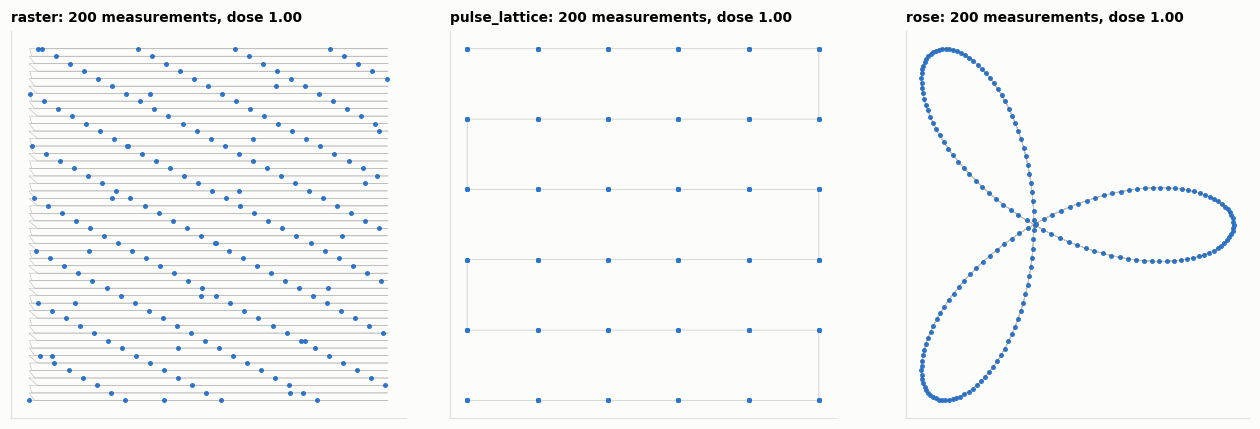

In [5]:
fair = sp.Budget(fov_nm=BUDGET.fov_nm, duration_s=BUDGET.duration_s, rate_hz=BUDGET.rate_hz,
                 acquisitions=200, dose=1.0)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, name in zip(axes, ("raster", "pulse_lattice", "rose")):
    path = sp.make_path(name, fair)
    ax.plot(*path.xy.T, lw=0.4, color=INK2, alpha=0.35)
    ax.scatter(*path.events.T, s=5, color=BLUE)
    ax.set_title(f"{name}: {path.acquire.sum()} measurements, dose {path.dose.sum():.2f}", fontsize=9)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Changing a parameter is just passing it. Here is the path chosen in `PATH`, and the same
family with two of its parameters changed:

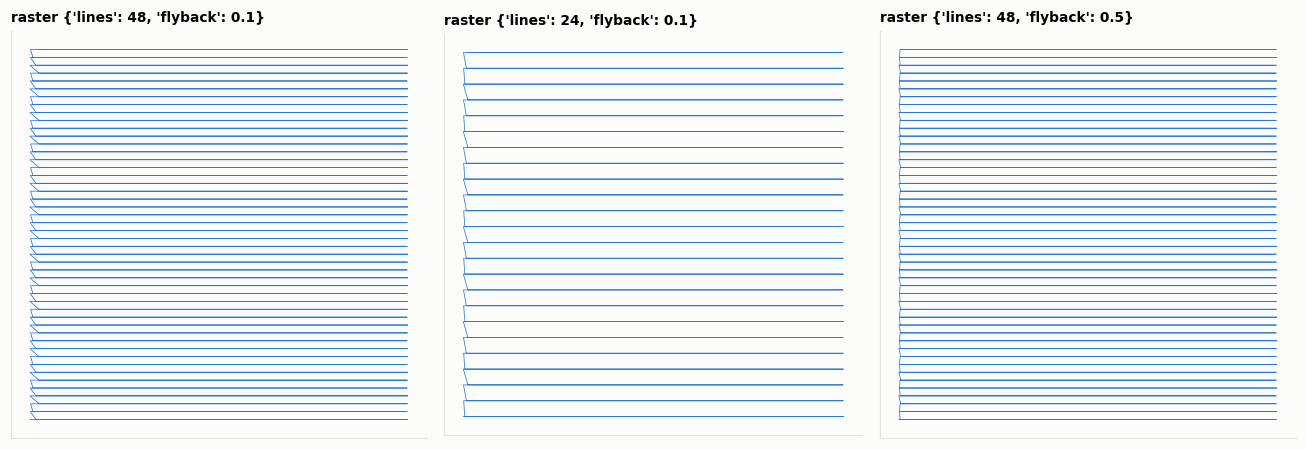

In [6]:
family, params = PATH
variants = [params, {**params, "lines": 24}, {**params, "flyback": 0.5}]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, p in zip(axes, variants):
    path = sp.make_path(family, BUDGET, **p)
    ax.plot(*path.xy.T, lw=0.5, color=BLUE)
    ax.set_title(f"{family} {tidy(p)}", fontsize=9)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Instrument model: two cases

**Case A, path → path.** The model says what the instrument does to the probe's motion:
lag, ringing, drift, coarse-stage jumps. Its output is a realized trajectory on the same
clock. The image is then formed the way a real microscope forms it: the signal is read
where the probe really was and drawn where it was told to be.

**Case B, image → image.** The model goes straight from the ideal image to the image the
user sees, without a realized trajectory. The commanded path still matters, because it
says where and when each part of the image is scanned, so a drift warps a raster into a
shear and a spiral into a swirl.

In [7]:
for title, registry in (("case A, path -> path", sp.INSTRUMENTS),
                        ("case B, image -> image", sp.IMAGE_MODELS)):
    print(title)
    for name, fn in registry.items():
        print(f"   {name:15s} {sp.parameters(name)}")
        print(f"   {'':15s} {fn.__doc__.strip().splitlines()[0]}")
    print()

case A, path -> path
   ideal           {}
                   Perfect tracking: realized = commanded.
   lowpass         {'bandwidth_hz': 1500.0, 'delay_s': 0.0, 'hold': 'linear'}
                   First-order scanner (-3 dB at bandwidth_hz, time constant tau = 1 / 2 pi
   resonant        {'resonance_hz': 1500.0, 'damping': 0.15, 'delay_s': 0.0}
                   Second-order (mass-spring) scanner, e.g. a piezo tube: overshoot and ringing.
   drift           {'vx_nm_s': 2.0, 'vy_nm_s': 1.0}
                   Linear drift of the sample under the probe.
   noise           {'sd_nm': 2.0, 'seed': 0}
                   White position noise.
   stage_moves     {'r_fine_nm': 5000.0, 'landing_sd_nm': 50.0, 'seed': 0}
                   Coarse stage + fine piezo: each coarse move lands with a random offset that stays.
   creep           {'amount': 0.01, 'tau_s': 10.0}
                   Piezo creep: a slow extra extension, a fraction of the distance from the start.
   chain           {'stage

### Case A: what the scanner does to the path

`simulate` returns the realized path; `image_as_acquired` forms the image from it. Three
models, one of them a chain of several (lag, then coarse-stage moves, then drift, then
noise), all on the path from `PATH`:

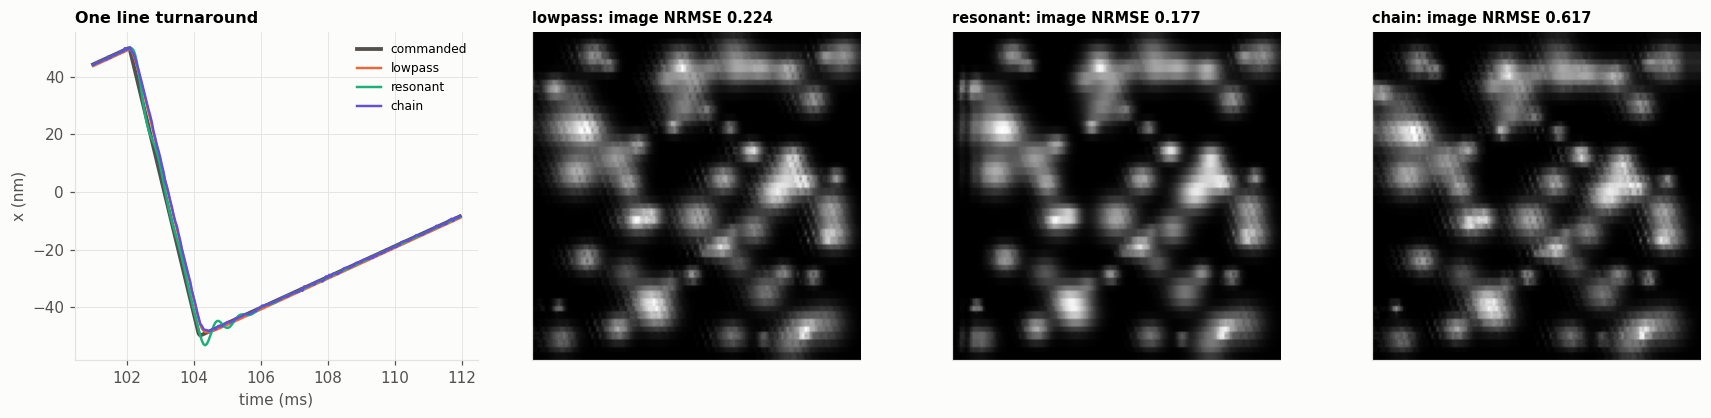

In [8]:
commanded = sp.make_path(*PATH[:1], BUDGET, **PATH[1])
case_a = {
    "lowpass": INSTRUMENT,
    "resonant": ("resonant", {"resonance_hz": 1500, "damping": 0.15}),
    "chain": ("chain", {"stages": [("lowpass", {"bandwidth_hz": 1500}),
                                   ("drift", {"vx_nm_s": 5.0, "vy_nm_s": 2.0}),
                                   ("noise", {"sd_nm": 0.3})]}),
}
line = int(BUDGET.n / PATH[1]["lines"])
window = slice(5 * line - 60, 5 * line + 160)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
axes[0].plot(commanded.t[window] * 1e3, commanded.xy[window, 0], color=INK2, lw=2.5, label="commanded")
for (label, (name, p)), color, ax in zip(case_a.items(), (ORANGE, AQUA, VIOLET), axes[1:]):
    realized = sp.simulate(commanded, name, seed=0, **p)
    axes[0].plot(commanded.t[window] * 1e3, realized.xy[window, 0], color=color, lw=1.6, label=label)
    image = sp.image_as_acquired(commanded, realized, SAMPLE)
    nrmse = sp.evaluate(commanded, realized, SAMPLE, ["image_nrmse"])["image_nrmse"]
    show_image(ax, image, f"{label}: image NRMSE {nrmse:.3f}", BUDGET)
axes[0].set_xlabel("time (ms)"); axes[0].set_ylabel("x (nm)")
axes[0].set_title("One line turnaround"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Case B: from the ideal image straight to the distorted image

`make_image(sample, commanded, model, **params)` returns the image directly. Each model
below is applied to the same raster, and drift is also shown on a spiral, to make the
point that an image model still depends on the path.

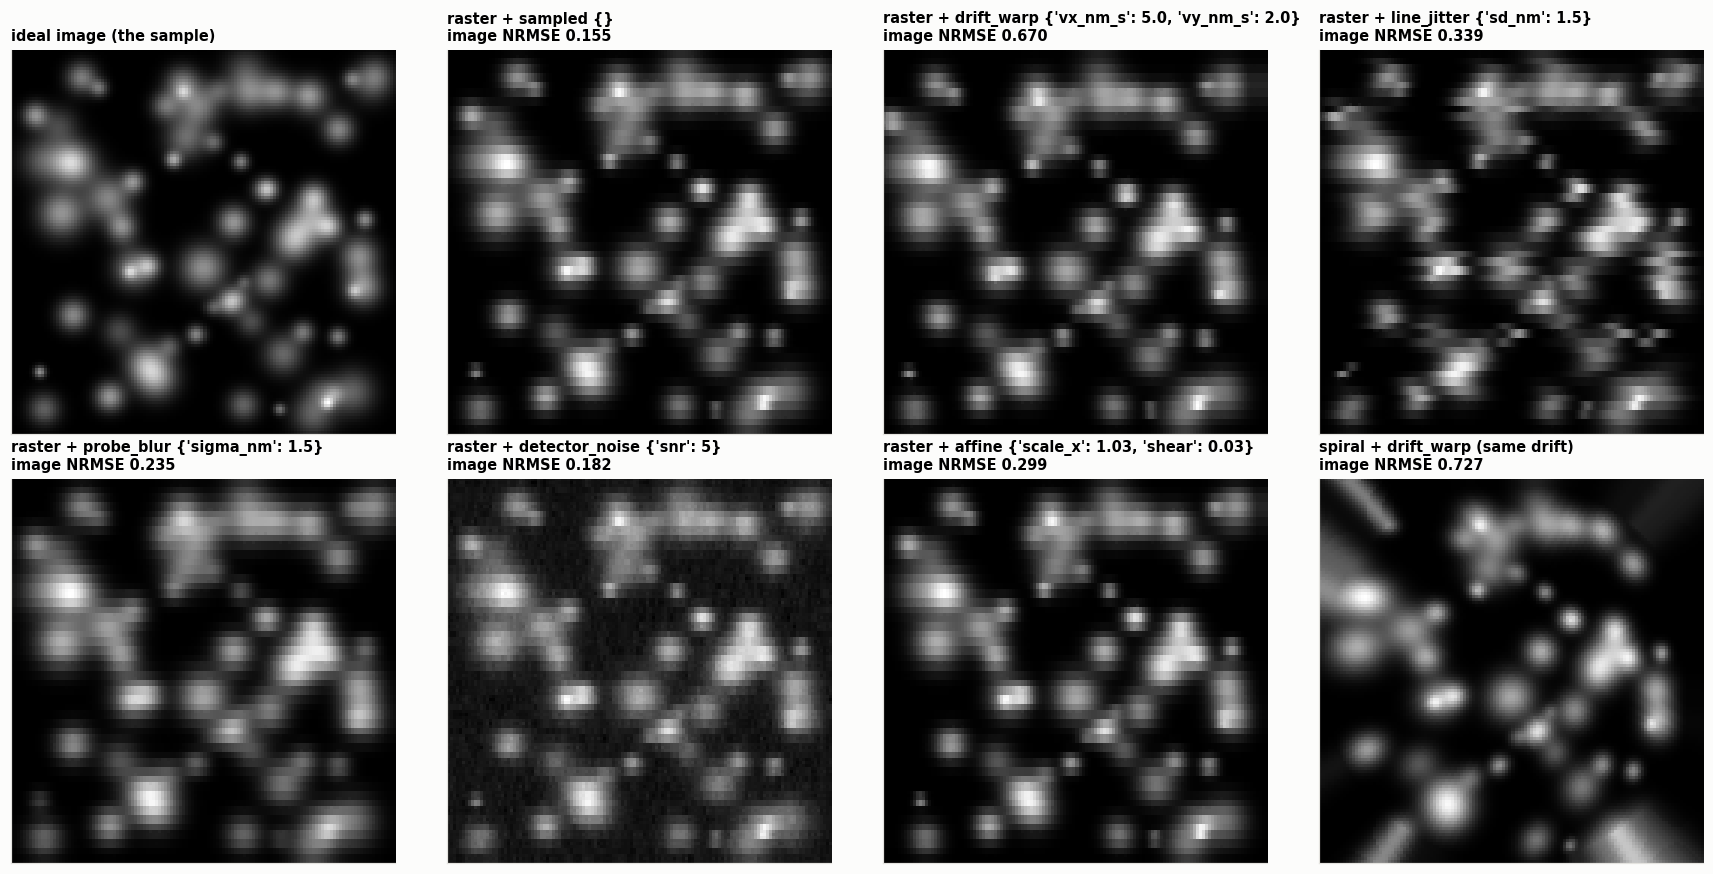

In [9]:
case_b = [("sampled", {}), IMAGE_MODEL, ("line_jitter", {"sd_nm": 1.5}),
          ("probe_blur", {"sigma_nm": 1.5}), ("detector_noise", {"snr": 5}),
          ("affine", {"scale_x": 1.03, "shear": 0.03})]
spiral = sp.make_path("spiral", BUDGET)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
show_image(axes[0, 0], SAMPLE.image, "ideal image (the sample)", BUDGET)
for ax, (name, p) in zip(list(axes.flat)[1:], case_b):
    image = sp.make_image(SAMPLE, commanded, name, **p)
    nrmse = sp.METRICS["image_nrmse"](image, SAMPLE)
    show_image(ax, image, f"raster + {name} {tidy(p)}\nimage NRMSE {nrmse:.3f}", BUDGET)
image = sp.make_image(SAMPLE, spiral, IMAGE_MODEL[0], **IMAGE_MODEL[1])
show_image(axes[1, 3], image, f"spiral + {IMAGE_MODEL[0]} (same drift)\n"
           f"image NRMSE {sp.METRICS['image_nrmse'](image, SAMPLE):.3f}", BUDGET)
plt.tight_layout(); plt.show()

### The two cases fit together

`from_path` turns any case-A model into a case-B model, and drift modelled either way
gives the same image. So a study can start in whichever language is natural for the
effect (a scanner transfer function is a path model; blur and detector noise are image
models) and still feed the same metrics and optimisers.

In [10]:
a = sp.run(PATH, INSTRUMENT, ["image_nrmse"], BUDGET, SAMPLE)
b = sp.run(PATH, ("from_path", {"path_model": INSTRUMENT[0], "path_params": INSTRUMENT[1]}),
           ["image_nrmse"], BUDGET, SAMPLE)
print(f"case A route   : image NRMSE {a.scores['image_nrmse']:.4f}")
print(f"case B from_path: image NRMSE {b.scores['image_nrmse']:.4f}   same image: {np.allclose(a.image, b.image)}")
c = sp.run(PATH, ("drift", IMAGE_MODEL[1]), ["image_nrmse"], BUDGET, SAMPLE)
d = sp.run(PATH, IMAGE_MODEL, ["image_nrmse"], BUDGET, SAMPLE)
print(f"drift as a path model : {c.scores['image_nrmse']:.4f}")
print(f"drift as an image model: {d.scores['image_nrmse']:.4f}   same image: {np.allclose(c.image, d.image)}")

case A route   : image NRMSE 0.2241
case B from_path: image NRMSE 0.2241   same image: True
drift as a path model : 0.6702
drift as an image model: 0.6702   same image: True


## 3. Evaluation: swappable quality and distortion metrics

Every metric is a named function that returns one number, and there are two kinds:

* **path metrics** compare the commanded and realized trajectories (trajectory error,
  distortion after removing shift and rotation, coverage, feature positions, coarse-stage
  moves…). They need a case-A model.
* **image metrics** compare the image the user sees with the ideal image. They work with
  both cases.

Swapping the evaluation function means passing a different name.

In [11]:
print(f"{'metric':27s} {'kind':6s} {'better':7s} meaning")
for name, fn in sp.METRICS.items():
    better = "higher" if fn.higher_is_better else "lower"
    print(f"{name:27s} {fn.kind:6s} {better:7s} {fn.__doc__.strip().splitlines()[0][:70]}")

metric                      kind   better  meaning
rms_error_nm                path   lower   RMS distance between commanded and realized positions.
max_error_nm                path   lower   Worst-case distance between commanded and realized positions.
local_misalignment_nm       path   lower   RMS left after the best overall shift and rotation (shape error), nm.
placement_error_p99_nm      path   lower   99th percentile of |realized - commanded|: the worst-placed samples, n
coverage                    path   higher  Fraction of image pixels with a realized measurement within one pixel 
max_gap_nm                  path   lower   Largest distance from any pixel to the nearest realized measurement.
image_nrmse                 image  lower   Image error as the user sees it, relative to the ideal image's contras
image_correlation           image  higher  Pearson correlation between the image the user sees and the ideal imag
image_nrmse_oracle          path   lower   Image error if the tru

In [12]:
case_a_run = sp.run(PATH, INSTRUMENT, None, BUDGET, SAMPLE)       # None = every metric that applies
case_b_run = sp.run(PATH, IMAGE_MODEL, None, BUDGET, SAMPLE)
print(f"{'metric':27s} {'case A: ' + INSTRUMENT[0]:>18s} {'case B: ' + IMAGE_MODEL[0]:>22s}")
for name in case_a_run.scores:
    b = case_b_run.scores.get(name)
    print(f"{name:27s} {case_a_run.scores[name]:18.3f} {('%22.3f' % b) if b is not None else '%22s' % '(path metric)'}")

metric                         case A: lowpass     case B: drift_warp
rms_error_nm                             1.652          (path metric)
max_error_nm                             5.357          (path metric)
local_misalignment_nm                    1.652          (path metric)
placement_error_p99_nm                   5.093          (path metric)
coverage                                 0.751          (path metric)
max_gap_nm                               1.323          (path metric)
image_nrmse                              0.224                  0.670
image_correlation                        0.975                  0.772
image_nrmse_oracle                       0.155          (path metric)
feature_position_error_nm                0.006          (path metric)
noise_sensitivity_nm                     0.000          (path metric)
stage_moves                              0.000          (path metric)
switch_confidence                        1.000          (path metric)
path_length_um      

Adding a new evaluation function takes one decorated function, written here in the
notebook. This one measures how well edges are reproduced (the error in the image
gradient), which matters more than overall brightness for locating features. From now on
it can be used by name anywhere, including by the optimisers below.

In [13]:
@sp.register_metric("edge_error", kind="image")
def edge_error(image, sample):
    "RMS error of the image gradient, relative to the ideal image's gradient."
    gi, gs = np.gradient(image), np.gradient(sample.image)
    num = sum(np.mean((a - b) ** 2) for a, b in zip(gi, gs))
    return np.sqrt(num / sum(np.mean(b ** 2) for b in gs))

for model in (INSTRUMENT, IMAGE_MODEL):
    r = sp.run(PATH, model, ["image_nrmse", "edge_error"], BUDGET, SAMPLE)
    print(f"{model[0]:12s} image_nrmse {r.scores['image_nrmse']:.3f}   edge_error {r.scores['edge_error']:.3f}")

lowpass      image_nrmse 0.224   edge_error 0.638
drift_warp   image_nrmse 0.670   edge_error 1.021


## 4. Parameter exploration and optimisation

Both optimisers take the same arguments (path family, what to explore, score, instrument
model) and return the same thing: every point they tried, with its scores, and the best
point.

* `grid_search` tries every point of a grid. With one or two parameters it's cheap and
  shows the whole landscape.
* `gp_search` is GP-based (Bayesian) optimisation: a Gaussian process models the score
  from the points tried so far and the next point is the one with the highest expected
  improvement. It needs far fewer runs and handles continuous parameters directly.

Here both explore the raster's line count and flyback fraction on the 1.5 kHz scanner.

In [14]:
lines = list(range(16, 129, 8))
flyback = list(np.round(np.linspace(0.05, 0.8, 16), 3))
grid_rows, grid_best = sp.grid_search(PATH[0], {"lines": lines, "flyback": flyback}, SCORE,
                                      instrument=INSTRUMENT, budget=BUDGET, sample=SAMPLE)
gp_rows, gp_best = sp.gp_search(PATH[0], SPACE, SCORE, instrument=INSTRUMENT, n_evals=25,
                                budget=BUDGET, sample=SAMPLE, seed=0)
print(f"grid search: {len(grid_rows):3d} runs, best lines {grid_best['lines']}, "
      f"flyback {grid_best['flyback']:.3f}, {SCORE} {grid_best[SCORE]:.4f}")
print(f"GP search  : {len(gp_rows):3d} runs, best lines {gp_best['lines']}, "
      f"flyback {gp_best['flyback']:.3f}, {SCORE} {gp_best[SCORE]:.4f}")

grid search: 240 runs, best lines 56, flyback 0.550, image_nrmse 0.1642
GP search  :  25 runs, best lines 55, flyback 0.523, image_nrmse 0.1622


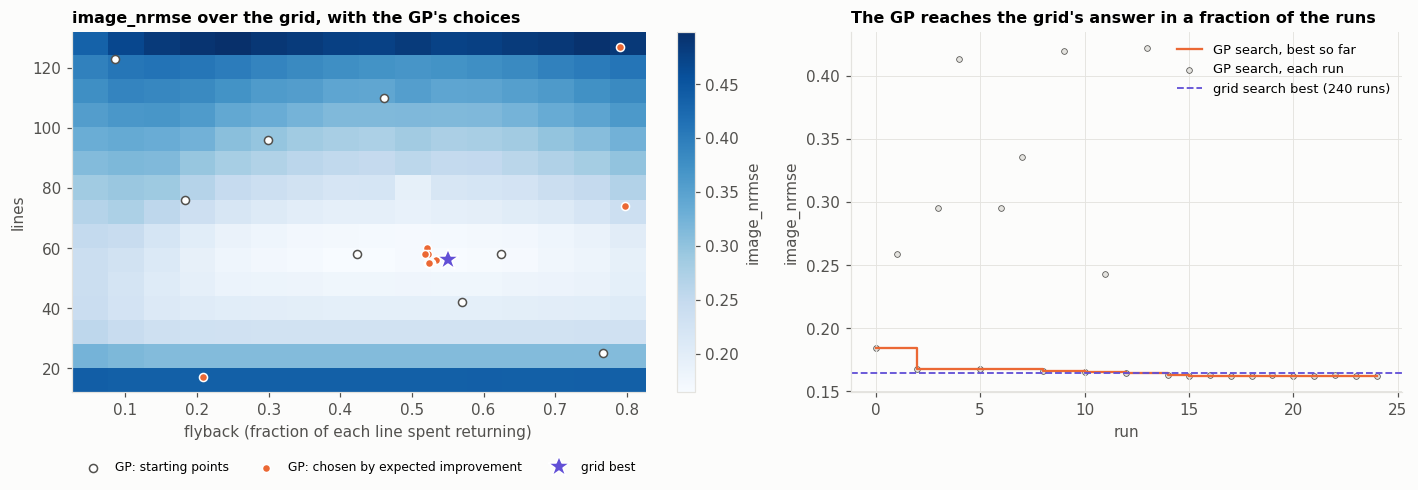

In [15]:
grid = np.array([r[SCORE] for r in grid_rows]).reshape(len(lines), len(flyback))
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = a.imshow(grid, origin="lower", aspect="auto", cmap="Blues",
              extent=[flyback[0] - 0.025, flyback[-1] + 0.025, lines[0] - 4, lines[-1] + 4])
fig.colorbar(im, ax=a, fraction=0.046, label=SCORE)
initial = [r for r in gp_rows if r["phase"] == "initial"]
guided = [r for r in gp_rows if r["phase"] == "gp"]
a.scatter([r["flyback"] for r in initial], [r["lines"] for r in initial], s=28, color="white",
          edgecolor=INK2, label="GP: starting points")
a.scatter([r["flyback"] for r in guided], [r["lines"] for r in guided], s=28, color=ORANGE,
          edgecolor="white", label="GP: chosen by expected improvement")
a.plot(grid_best["flyback"], grid_best["lines"], "*", ms=15, color=VIOLET, mec="white", label="grid best")
a.set_xlabel("flyback (fraction of each line spent returning)"); a.set_ylabel("lines")
a.set_title(f"{SCORE} over the grid, with the GP's choices"); a.grid(False)
a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)

b.plot([r["step"] for r in gp_rows], [r["best_so_far"] for r in gp_rows], color=ORANGE,
       drawstyle="steps-post", label="GP search, best so far")
b.scatter([r["step"] for r in gp_rows], [r[SCORE] for r in gp_rows], s=14, color=GRID,
          edgecolor=INK2, linewidth=0.5, label="GP search, each run")
b.axhline(grid_best[SCORE], color=VIOLET, ls="--", lw=1.2,
          label=f"grid search best ({len(grid_rows)} runs)")
b.set_xlabel("run"); b.set_ylabel(SCORE); b.legend(fontsize=8.5)
b.set_title("The GP reaches the grid's answer in a fraction of the runs")
plt.tight_layout(); plt.show()

The landscape has one clear valley, and both searches find it: about 55 lines, with the
beam spending roughly half of each line on the way back. In other words, on a
lag-limited scanner the best raster is close to a symmetric triangle wave, where the
return is as gentle as the trace. That's not what you'd pick by hand.

The answer belongs to the instrument, not to the path family. Swap the instrument (or
the metric) and run the same search again; nothing else changes:

In [16]:
for model, score in ((INSTRUMENT, SCORE), ("ideal", SCORE), (IMAGE_MODEL, SCORE),
                     (INSTRUMENT, "edge_error")):
    rows, best = sp.gp_search(PATH[0], SPACE, score, instrument=model, n_evals=25,
                              budget=BUDGET, sample=SAMPLE, seed=0)
    name = model if isinstance(model, str) else model[0]
    print(f"{name:12s} {score:12s}: best lines {best['lines']:3d}, flyback {best['flyback']:.2f}, "
          f"{score} {best[score]:.3f}")

lowpass      image_nrmse : best lines  55, flyback 0.52, image_nrmse 0.162
ideal        image_nrmse : best lines 128, flyback 0.80, image_nrmse 0.028
drift_warp   image_nrmse : best lines 127, flyback 0.21, image_nrmse 0.655
lowpass      edge_error  : best lines  64, flyback 0.51, edge_error 0.358


### Other searches, and constraints

`grid_search` and `gp_search` are two of five searches with the same arguments and the
same output; `sp.SEARCHES` holds them by name. Each gets the same budget here, 25 runs
(the grid gets 5 levels per parameter).

A search can also be told what a candidate must not do. `sp.limits(...)` turns rules
such as "the probe never moves faster than 15 µm/s" into constraints; a candidate that
breaks one is infeasible, and the best row is always the best *feasible* one.

In [17]:
for name, search in sp.SEARCHES.items():
    options = {"levels": 5} if name == "grid" else {"n_evals": 25}
    rows, best = search(PATH[0], SPACE, SCORE, INSTRUMENT, budget=BUDGET, sample=SAMPLE, **options)
    print(f"{name:8s} {len(rows):3d} runs: lines {best['lines']:3d}, flyback {best['flyback']:.2f}, "
          f"{SCORE} {best[SCORE]:.4f}")

speed_limit = sp.limits(at_most={"realized_speed_peak_um_s": 15})
rows, best = sp.gp_search(PATH[0], SPACE, SCORE, INSTRUMENT, n_evals=25, constraints=speed_limit,
                          budget=BUDGET, sample=SAMPLE)
print(f"\nwith the probe kept under 15 µm/s: lines {best['lines']}, flyback {best['flyback']:.2f}, "
      f"{SCORE} {best[SCORE]:.4f}, peak speed {best['realized_speed_peak_um_s']:.1f} µm/s, "
      f"feasible {best['feasible']}; {sum(not r['feasible'] for r in rows)} of {len(rows)} runs broke the limit")

grid      25 runs: lines  44, flyback 0.42, image_nrmse 0.1749
random    25 runs: lines  50, flyback 0.37, image_nrmse 0.1717
pattern   25 runs: lines  54, flyback 0.52, image_nrmse 0.1635
de        25 runs: lines  55, flyback 0.47, image_nrmse 0.1621
gp        25 runs: lines  55, flyback 0.52, image_nrmse 0.1622

with the probe kept under 15 µm/s: lines 45, flyback 0.52, image_nrmse 0.1759, peak speed 14.2 µm/s, feasible True; 20 of 25 runs broke the limit


## 5. The whole loop in one call

This is the same pipeline written as one function, driven by the choices in section 0.
`examples/05_full_pipeline.py` is the same thing as a script.

In [18]:
def full_pipeline(path, instrument, score, space, optimiser="gp", budget=BUDGET, sample=SAMPLE):
    family, start = path
    before = sp.run(path, instrument, [score], budget, sample)                     # stages 1-3
    search = sp.SEARCHES[optimiser]                                                # stage 4
    rows, best = search(family, space, score, instrument=instrument, budget=budget, sample=sample,
                        fixed={k: v for k, v in start.items() if k not in space})
    found = {k: best[k] for k in space}
    after = sp.run((family, {**start, **found}), instrument, [score], budget, sample)
    return before, after, found, len(rows)

for instrument in (INSTRUMENT, IMAGE_MODEL):
    before, after, found, n = full_pipeline(PATH, instrument, SCORE, SPACE)
    name = instrument[0]
    print(f"{name:11s} {PATH[0]} {tidy(PATH[1])} -> {tidy(found)} in {n} runs: "
          f"{SCORE} {before.scores[SCORE]:.3f} -> {after.scores[SCORE]:.3f}")

lowpass     raster {'lines': 48, 'flyback': 0.1} -> {'lines': 55, 'flyback': 0.525} in 28 runs: image_nrmse 0.224 -> 0.162
drift_warp  raster {'lines': 48, 'flyback': 0.1} -> {'lines': 127, 'flyback': 0.058} in 28 runs: image_nrmse 0.670 -> 0.655


## Swapping components: a summary

| to change… | do this |
|---|---|
| the path | `PATH = ("lissajous", {"nx": 29, "ny": 30})`; list options with `sp.parameters(name)` |
| the instrument (case A) | `INSTRUMENT = ("resonant", {...})` or a `"chain"` of models |
| the instrument (case B) | `IMAGE_MODEL = ("probe_blur", {"sigma_nm": 2})`; any case-A model via `"from_path"` |
| the evaluation function | `SCORE = "edge_error"` (image metrics work with both cases) |
| the optimiser | `sp.SEARCHES["grid" / "random" / "pattern" / "de" / "gp"](family, space, …)` |
| what a candidate must respect | `constraints=sp.limits(at_most={...}, at_least={...})` |
| add a new component | write one function with `@sp.register_path`, `@sp.register_instrument`, `@sp.register_image_model` or `@sp.register_metric` |

Instrument parameters here are illustrative, not calibrated against a real microscope.